# Marmousi01 — true velocity model: read & view

First step of the pre-refactor FWI-loop test: load and inspect the
Marmousi01 true velocity model — `float32`, shape 128×256 (a downsampled
Marmousi grid: 128 depth samples × 256 lateral samples).

The file lives in the sibling benchmark project
(`projetos/Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy`); this
notebook stays in `ls-fwi` and only READS it.

Reference: the classic Marmousi1 model spans ~1500–5500 m/s
(water layer ~1500 m/s at the top).

In [1]:
import numpy as np
from pathlib import Path

CANDIDATES = [
    Path("../../Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy"),   # repo root
    Path("../../../Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy"),  # notebooks/
    Path("/tgdesenv/src/proj0/ntbs/doutorado/5semestre.2024.2/estudo.orientado/"
         "projetos/Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy"),  # host
    Path("/tgdesenv/doutorado/5semestre.2024.2/estudo.orientado/"
         "projetos/Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy"),  # container
]
MARM = next(c for c in CANDIDATES if c.exists())
m = np.load(MARM)

print(f"file : {MARM}")
print(f"shape: {m.shape}  dtype: {m.dtype}")
print(f"range: {m.min():.1f} .. {m.max():.1f}")
print(f"mean : {m.mean():.1f}")

file : ../../Benchmarks_FWI_ML/Dados/Marmousi01/marm_true.npy
shape: (128, 256)  dtype: float32
range: 1500.0 .. 4699.9
mean : 2682.2


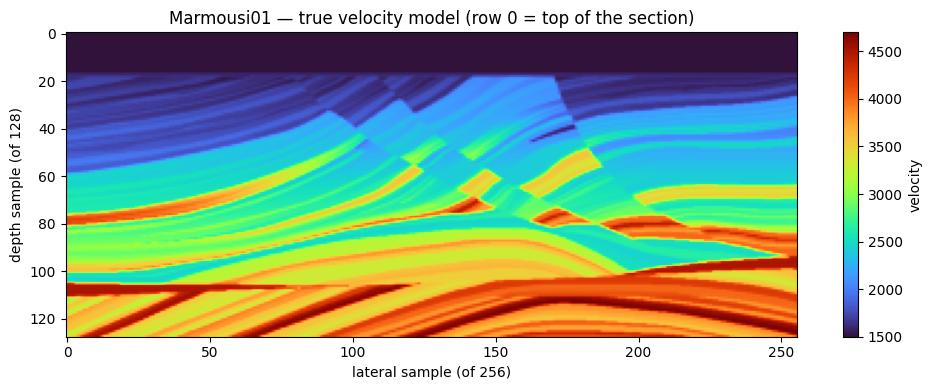

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(m, cmap="turbo", aspect="auto", origin="upper")
ax.set_xlabel("lateral sample (of 256)")
ax.set_ylabel("depth sample (of 128)")
ax.set_title("Marmousi01 — true velocity model (row 0 = top of the section)")
fig.colorbar(im, ax=ax, label="velocity")
plt.tight_layout()
plt.show()

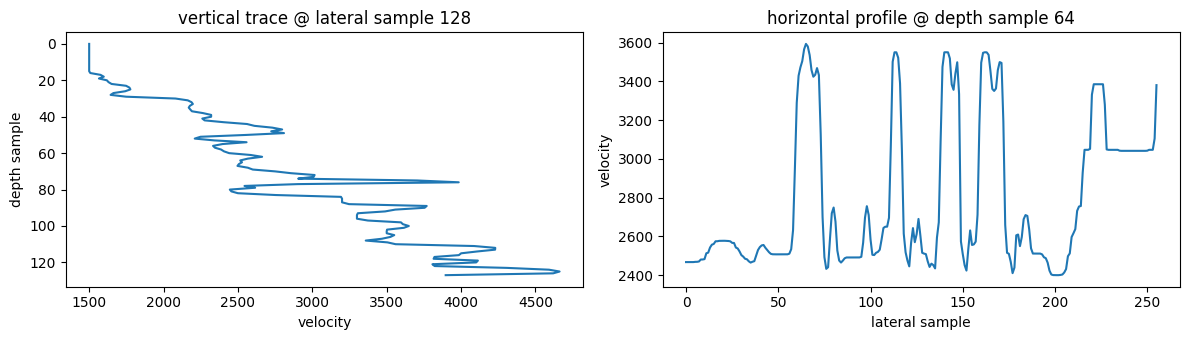

In [3]:
# quick profiles: one velocity trace (vertical) and one horizontal
# layer profile — useful sanity checks before wiring an FWI loop
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 3.5))
axL.plot(m[:, m.shape[1] // 2], np.arange(m.shape[0]))
axL.invert_yaxis()
axL.set_xlabel("velocity")
axL.set_ylabel("depth sample")
axL.set_title(f"vertical trace @ lateral sample {m.shape[1] // 2}")
axR.plot(m[m.shape[0] // 2, :])
axR.set_xlabel("lateral sample")
axR.set_ylabel("velocity")
axR.set_title(f"horizontal profile @ depth sample {m.shape[0] // 2}")
plt.tight_layout()
plt.show()

## From Marmousi to the pipeline's model grid

The AE's generator works on **(672, 800)**: `Utils.find_size(depth=5)`
takes the raw (680, 800) models down to the largest sizes divisible by
2⁵ (the decoder's 5 upsampling levels), and the latent grid
(1, 512, 21, 25) is exactly 672/32 × 800/32.

The Marmousi file (128×256) is *smaller* in both dimensions, so this is
not a crop — it is a **resample** (bilinear upscale) to 672×800,
followed by the campaign's normalization.

**Normalization** (from `src/preprocessing/pipeline.py`, exactly as the
apps invoke it): `BatchAbsMaxScaler` is fitted on the TRAIN split's true
models — `absmax = max(|X|, axis=(0,1))` over the (900, 680, 800) stack,
i.e. one abs-max **per lateral column** — and every model (train and
test) is divided by it. The files are raw m/s; after scaling, velocities
become fractions of their column's train-set maximum (the context
figures' 0.4–0.9 colorbars). The Marmousi gets the same treatment:
resample FIRST (so the columns align), then divide by the same
per-column absmax.

resampled: (672, 800), range 1500.0..4699.0 m/s


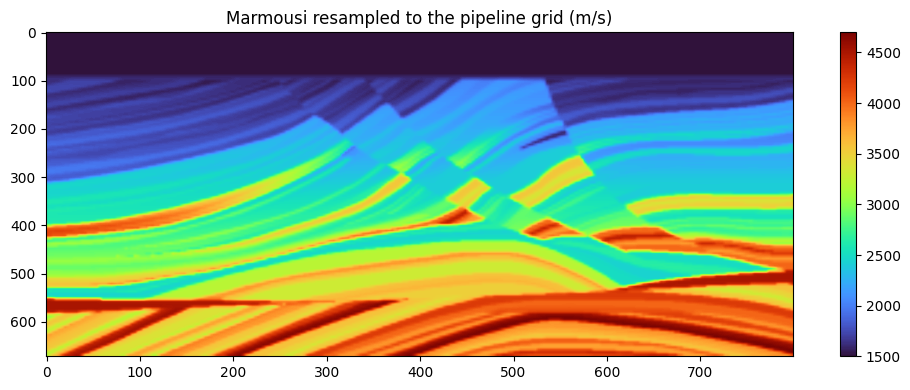

In [4]:
# resample 128x256 -> (672, 800), still in m/s
import torch

NZ, NX = 672, 800                     # nz_cut x nx_cut (find_size depth=5)
m_up = torch.nn.functional.interpolate(
    torch.from_numpy(m[None, None].astype(np.float32)),
    size=(NZ, NX), mode="bilinear", align_corners=False)[0, 0].numpy()
print(f"resampled: {m_up.shape}, range {m_up.min():.1f}..{m_up.max():.1f} m/s")

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(m_up, cmap="turbo", aspect="auto")
ax.set_title("Marmousi resampled to the pipeline grid (m/s)")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

<2026-11-25 23:05:37> [ INFO ] FINDING OUT DATA FORMAT

<2026-11-25 23:05:37> [ INFO ] 	Filename: /gemini/tg/ntbs/doutorado/5semestre/estudo.orientado/deeptomograph_data/data_new_and_bigger/./input_suave_1.npy

<2026-11-25 23:05:37> [ INFO ] 	File shape: (680, 800, 15)

<2026-11-25 23:05:37> [ INFO ] 	Target z_len (newer dataset): 680

---------------------------------------------------
<2026-11-25 23:05:37> [ NEW DATA ] Building Deep Tomography models...
---------------------------------------------------
---------------------------------------------------
---------------------------------------------------
---------------------------------------------------
<2026-11-25 23:05:37> Spliting samples into train and test!
---------------------------------------------------
<2026-11-25 23:05:37> [ INFO ] Total nmb of samples: 1000

<2026-11-25 23:05:37> [ INFO ] Percentage of test samples: 10.0%

<2026-11-25 23:05:37> [ DEBUG ] set1_indexes.shape[0]+set2_indexes.shape[0] == nsamples        

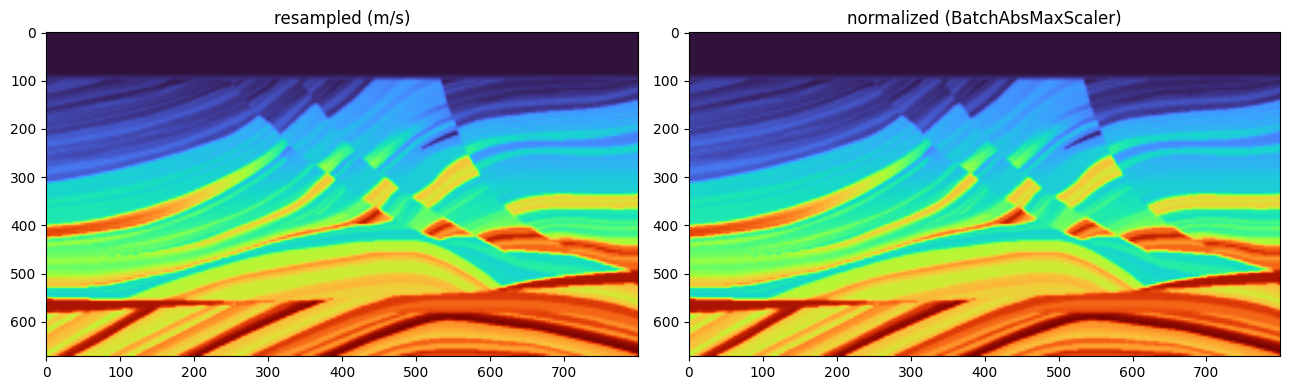

In [5]:
# the campaign's normalization: BatchAbsMaxScaler fitted on the TRAIN
# split (src/preprocessing/pipeline.py) — one abs-max per lateral column
from src.apps.global_vars import load_data_and_models

(data_basedir, dirs, train_data, test_data,
 train_models, test_models, train_indexes, test_indexes, newer) = \
    load_data_and_models(data='deep', data_type='deep', data_resolution='high',
                         data_max_samples=None, test_perc=0.1, seed=79)

raw_train = train_models.get_true_models().get_models()   # (900, 680, 800), raw m/s
absmax = np.max(np.abs(raw_train), axis=(0, 1))           # (800,) per lateral column
print(f"train true models: {raw_train.shape}, range "
      f"{raw_train.min():.1f}..{raw_train.max():.1f} m/s")
print(f"absmax per column: {absmax.shape}, "
      f"range {absmax.min():.1f}..{absmax.max():.1f} m/s")

m_ds = m_up / absmax                                      # broadcast over (672, 800)
print(f"normalized Marmousi: range {m_ds.min():.3f}..{m_ds.max():.3f} "
      "(context figures show ~0.4..0.9)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.imshow(m_up, cmap="turbo", aspect="auto"); ax1.set_title("resampled (m/s)")
ax2.imshow(m_ds, cmap="turbo", aspect="auto"); ax2.set_title("normalized (BatchAbsMaxScaler)")
plt.tight_layout()
plt.show()

## Invert: latent optimization against the Marmousi target

Reuses the campaign machinery exactly as `task_processing.py` does:
`EncoderDecoder` loaded from the refit checkpoint via skorch
(`load_params`), split into Encoder + Generator, then
`SkorchGeneratorInversionBuilder` with the campaign's best config:
**trained init** — the starting latent is `Encoder(x)` of train-split
position 10 (dataset example 182), the SAME initial latent as every
`trained` run of the campaign (hence the identical first column in the
exploratory traverse figure). Sequence per the source: `initialize()` →
`set_latent(...)` → `partial_fit(...)` — never re-initialize after
setting the latent. lr=0.1, 1000 epochs; the Marmousi target is the
resampled, normalized model from the previous cells. (Per the
reachability result, `zeros`/`random` reach the same floor — the
zeros variant is kept in the control cells below.)

In [22]:
import sys, json, re, ast, urllib.request
import torch.nn as nn
from pathlib import Path

REPO = Path("..").resolve() if (Path("..") / "src").exists() else Path(".").resolve()
sys.path.insert(0, str(REPO))

import ml_collections
from src.processing.ml_models import EncoderDecoder
from src.processing.ml_models_builder import (ScoredSkorchModel,
    SkorchEncoderModelBuilder, SkorchGeneratorModelBuilder,
    SkorchGeneratorInversionBuilder)
from src.experiment_tracking.mlflow_utils import MLFlowUtils

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# --- campaign wiring, reconstructed from the runs' logged params ---
BEST_RUN = "aa821c27efd64fdbbe99012a8ebc96ca"   # best inversion run
REFIT_RUN = "9247757e7e0f49459ee4fe8e897fcd14"  # encdec 5x5, seed 79
MLFLOW = "http://gr14sm02.ep.petrobras.com.br:31947/api/2.0/mlflow"

def run_params(run_id):
    with urllib.request.urlopen(f"{MLFLOW}/runs/get?run_id={run_id}",
                                timeout=30) as r:
        data = json.loads(r.read().decode())["run"]["data"]
    return {x["key"]: x["value"] for x in data["params"]}

inv_params = run_params(BEST_RUN)
refit_params = run_params(REFIT_RUN)

# checkpoint: the exact file the best run loaded (logged in its grid)
ckpt = re.search(r"'weights_files': \['([^']+)'\]",
                 inv_params["inference_grid"]).group(1)
print("checkpoint:", ckpt)

# module kwargs: the refit's logged module__* values, typed via
# literal_eval (strings like '5,5' -> (5, 5), '0.2' -> 0.2, 'False' -> False;
# non-literals like unembed_type='paper' stay as strings)
module_kwargs = {}
for k, v in refit_params.items():
    if not k.startswith("module__") or k == "module__attention_config":
        continue
    try:
        module_kwargs[k] = ast.literal_eval(v)
    except (ValueError, SyntaxError):
        module_kwargs[k] = v

# attention config: rebuilt exactly as global_vars does — ConfigDict over
# string_to_dict + the patches override. Note module__use_transformers is
# False for this refit, so the module never touches the attention path.
attention_config = ml_collections.ConfigDict(
    MLFlowUtils.string_to_dict(refit_params["module__attention_config"]))
attention_config.patches = ml_collections.ConfigDict({"size": (1, 1)})
module_kwargs["module__attention_config"] = attention_config

print("module kwargs:")
for k, v in sorted(module_kwargs.items()):
    print(f"   {k} = {v}")

autoencoder = ScoredSkorchModel(
    module=EncoderDecoder, device=device, seed=79, **module_kwargs)
autoencoder.initialize()
autoencoder.load_params(f_params=ckpt)

encoder = SkorchEncoderModelBuilder().build(
    autoencoder=autoencoder.module_, device=device)
encoder.initialize()
generator = SkorchGeneratorModelBuilder().build(
    autoencoder=autoencoder.module_, device=device)
generator.initialize()

# the campaign's forward logs latent.mean() every step — silence it here
from src.processing import ml_models as _mlm
_mlm.log.info = lambda *a, **k: None

inversion = SkorchGeneratorInversionBuilder().build(
    generator=generator.module_, latent_shape=(1, 512, 21, 25),
    latent_init="trained", seed=79,
    max_epochs=1000, device=device, lr=0.1)   # best campaign config
inversion.initialize()

# trained init: the SAME starting latent as the campaign's trained
# runs — Encoder(x) of train-split position 10 (dataset example
# 182), normalized with the train absmax and cropped like crop_data
x_init = ((raw_train[10] / absmax)[:672, :800])[None, None].astype(np.float32)
z0 = encoder.predict(torch.from_numpy(x_init).to(device))
inversion.module_.set_latent(z0)
print("trained latent set from train example", int(train_indexes[10]))

y = torch.from_numpy(m_ds[None, None].astype(np.float32)).to(device)
x = torch.zeros_like(y)                      # X is ignored by forward
inversion.partial_fit(x, y)
print("done — final train_loss:", inversion.history[-1]["train_loss"])


device: cuda
checkpoint: /gemini/tg/ntbs/doutorado/5semestre/estudo.orientado/deeptomograph_data/data_new_and_bigger/deeptomograph_results/predictions/REFIT__ENCDEC_ENCDEC_5x5_deep-data_high-res_full-samples_encdec-arch_2026-10-24T18.35.55__params.pt
module kwargs:
   module__attention_config = hidden_size: 768
patches:
  size: !!python/tuple
  - 1
  - 1
transformer:
  attention_dropout_rate: 0.0
  dropout_rate: 0.1
  mlp_dim: 3072
  num_heads: 12
  num_layers: 2
vis: false

   module__attention_img_size = (21, 25)
   module__attention_in_channels = 512
   module__batch_normalization = True
   module__conv_dilation_size = (1, 1)
   module__conv_kernel_size = (5, 5)
   module__dropout = 0.2
   module__in_channels = 1
   module__n_filters_init = 16
   module__out_channels = 1
   module__pool_kernel_size = (2, 2)
   module__pool_stride = (2, 2)
   module__transposed_conv_kernel_size = (2, 2)
   module__unembed_type = paper
   module__use_transformers = False
   module__verbose = True
   m

In [ ]:
# results — loss curve (with the pack's 95%/99% marks) and the recovery
losses = [h["train_loss"] for h in inversion.history]
final = losses[-1]
step95 = next(i for i, v in enumerate(losses) if v <= 1.05 * final)
step99 = next(i for i, v in enumerate(losses) if v <= 1.01 * final)
print(f"final MSE {final:.5f} | 95% at epoch {step95 + 1}, "
      f"99% at epoch {step99 + 1} (of {len(losses)})")

z = inversion.module_.latent.detach()
rec = generator.module_(z)[0, 0].detach().cpu().numpy()
tgt = y[0, 0].cpu().numpy()

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 4))
axL.plot(losses)
axL.axvline(step95, ls="--", lw=1, alpha=0.6)
axL.axvline(step99, ls=":", lw=1, alpha=0.6)
axL.set_yscale("log")
axL.set_xlabel("epoch (1 backpropagation step each)")
axL.set_ylabel("inversion loss (model-space MSE)")
axL.set_title("convergence — trained init, lr=0.1, 1000 epochs")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, img, ttl in zip(axes, [tgt, rec, tgt - rec],
                        ["target (Marmousi, normalized)",
                         "latent recovery (trained init)",
                         "difference"]):
    ax.imshow(img, cmap="turbo", aspect="auto")
    ax.set_title(ttl, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## Control: the campaign's three targets, re-run in this notebook

The three test-set targets of the campaign (positions 1/10/20 →
dataset examples 476/696/5), inverted again with the same machinery
and config as the Marmousi run (zeros init, lr=0.1, 1000 epochs).

The advantage: these re-runs optimize against the generator in
**eval mode** (the `GeneratorInversion.train()` override pins it),
while the campaign's logged curves were produced with the generator
in **train mode** (dropout active — the +2.1% median gap between the
logged trajectories and the reported eval MSEs, flagged in
`DATA_DICTIONARY.md`). Same targets, same config, same init — the
only difference is the mode fix.

In [24]:
# re-run the campaign's three targets (eval-mode generator)
test_true = test_models.get_true_models().get_models()  # (100, 680, 800) raw m/s
re_runs = {}
for mi in (1, 10, 20):
    t = (test_true[mi] / absmax)[:672, :800]   # train-fitted scaler, then crop
    y_t = torch.from_numpy(t[None, None].astype(np.float32)).to(device)
    inv = SkorchGeneratorInversionBuilder().build(
        generator=generator.module_, latent_shape=(1, 512, 21, 25),
        latent_init="zeros", seed=79,
        max_epochs=1000, device=device, lr=0.1)
    inv.initialize()
    inv.partial_fit(torch.zeros_like(y_t), y_t)
    losses_t = [h["train_loss"] for h in inv.history]
    final_t = losses_t[-1]
    s95 = next(i for i, v in enumerate(losses_t) if v <= 1.05 * final_t)
    s99 = next(i for i, v in enumerate(losses_t) if v <= 1.01 * final_t)
    ex_id = int(test_indexes[mi])
    re_runs[mi] = {"losses": losses_t, "ex_id": ex_id}
    print(f"pos {mi} (example {ex_id}): final MSE {final_t:.5f} | "
          f"95% at epoch {s95 + 1}, 99% at epoch {s99 + 1} (of {len(losses_t)})")

---------------------------------------------------
<2026-11-26 00:01:01> GeneratorInversion Constructor!!!
---------------------------------------------------


pos 1 (example 476): final MSE 0.00027 | 95% at epoch 579, 99% at epoch 895 (of 1000)
---------------------------------------------------
<2026-11-26 00:01:13> GeneratorInversion Constructor!!!
---------------------------------------------------
pos 10 (example 696): final MSE 0.00031 | 95% at epoch 679, 99% at epoch 862 (of 1000)
---------------------------------------------------
<2026-11-26 00:01:25> GeneratorInversion Constructor!!!
---------------------------------------------------
pos 20 (example 5): final MSE 0.00011 | 95% at epoch 511, 99% at epoch 855 (of 1000)


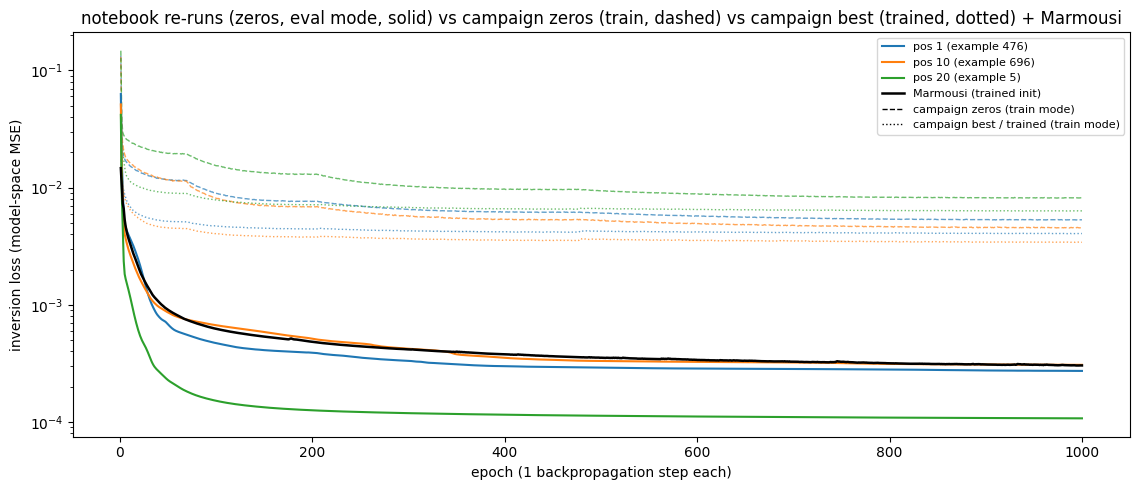

target                       notebook     z.traj     z.eval     b.traj     b.eval
Marmousi (resampled)          0.00030          —          —          —          —
pos 1 (ex 476)             0.00027    0.00532    0.00522    0.00405    0.00391
pos 10 (ex 696)             0.00031    0.00454    0.00436    0.00342    0.00325
pos 20 (ex 5)             0.00011    0.00817    0.00801    0.00633    0.00600
z = campaign zeros init (train mode) · b = campaign best run, trained init (train mode) · traj = logged trajectory end · eval = reported eval MSE


In [25]:
# comparison — solid: notebook re-runs (zeros, EVAL-mode generator);
# dashed: the campaign's zeros@0.1@1000ep logs (train mode) — isolates
# the eval-mode fix; dotted: the campaign's BEST run (trained init,
# same config, train mode) — the pack's reference, adds the init effect;
# black: the Marmousi run. All in absolute model-space MSE.
import pandas as pd
from matplotlib.lines import Line2D

DATA = Path("data") if Path("data/runs.csv").exists() else Path("notebooks/data")
runs = pd.read_csv(DATA / "runs.csv", dtype={"refit_short": str})

def campaign_run(init):
    c = runs[(runs["refit_short"] == "9247757e") & (runs["latent_init"] == init)
             & (runs["lr"] == 0.1) & (runs["max_epochs"] == 1000)]
    assert len(c) == 1, f"expected exactly one {init}@0.1@1000ep run"
    return c.iloc[0]["run_id"]

camp_ids = {"zeros": campaign_run("zeros"), "best": campaign_run("trained")}
hpe = pd.read_csv(DATA / "train_loss_per_example.csv", dtype={"refit_short": str})
camp_curves = {name: hpe[hpe["run_id"] == rid] for name, rid in camp_ids.items()}
pm = pd.read_csv(DATA / "inversion_per_model.csv", dtype={"refit_short": str})
camp_mse = {name: pm[pm["run_id"] == rid].set_index("model_idx")["mse"]
            for name, rid in camp_ids.items()}

fig, ax = plt.subplots(figsize=(11.5, 5))
colors = {1: "C0", 10: "C1", 20: "C2"}
styles = {"zeros": "--", "best": ":"}
for name in ("zeros", "best"):
    for mi in (1, 10, 20):
        g = camp_curves[name][camp_curves[name]["model_idx"] == mi].sort_values("step")
        ax.plot(g["step"], g["value"], ls=styles[name], lw=1,
                color=colors[mi], alpha=0.7)
for mi in (1, 10, 20):
    ax.plot(range(1, len(re_runs[mi]["losses"]) + 1), re_runs[mi]["losses"],
            ls="-", lw=1.5, color=colors[mi],
            label=f"pos {mi} (example {re_runs[mi]['ex_id']})")
ax.plot(range(1, len(losses) + 1), losses, color="k", lw=1.8,
        label="Marmousi (trained init)")
ax.set_yscale("log")
ax.set_xlabel("epoch (1 backpropagation step each)")
ax.set_ylabel("inversion loss (model-space MSE)")
ax.set_title("notebook re-runs (zeros, eval mode, solid) vs campaign zeros "
             "(train, dashed) vs campaign best (trained, dotted) + Marmousi")
handles, _ = ax.get_legend_handles_labels()
handles += [Line2D([], [], color="k", ls="--", lw=1,
                   label="campaign zeros (train mode)"),
            Line2D([], [], color="k", ls=":", lw=1,
                   label="campaign best / trained (train mode)")]
ax.legend(handles=handles, fontsize=8)
plt.tight_layout()
plt.show()

hdr = (f"{'target':26s} {'notebook':>10s} {'z.traj':>10s} {'z.eval':>10s}"
       f" {'b.traj':>10s} {'b.eval':>10s}")
print(hdr)
print(f"{'Marmousi (resampled)':26s} {final:10.5f} {'—':>10s} {'—':>10s}"
      f" {'—':>10s} {'—':>10s}")
for mi in (1, 10, 20):
    rows = {}
    for name in ("zeros", "best"):
        g = camp_curves[name][camp_curves[name]["model_idx"] == mi].sort_values("step")
        rows[name] = (float(g["value"].iloc[-1]), float(camp_mse[name].loc[mi]))
    nf = re_runs[mi]["losses"][-1]
    print(f"pos {mi} (ex {re_runs[mi]['ex_id']}){'':<9} {nf:10.5f}"
          f" {rows['zeros'][0]:10.5f} {rows['zeros'][1]:10.5f}"
          f" {rows['best'][0]:10.5f} {rows['best'][1]:10.5f}")
print("z = campaign zeros init (train mode) · b = campaign best run,"
      " trained init (train mode) · traj = logged trajectory end ·"
      " eval = reported eval MSE")


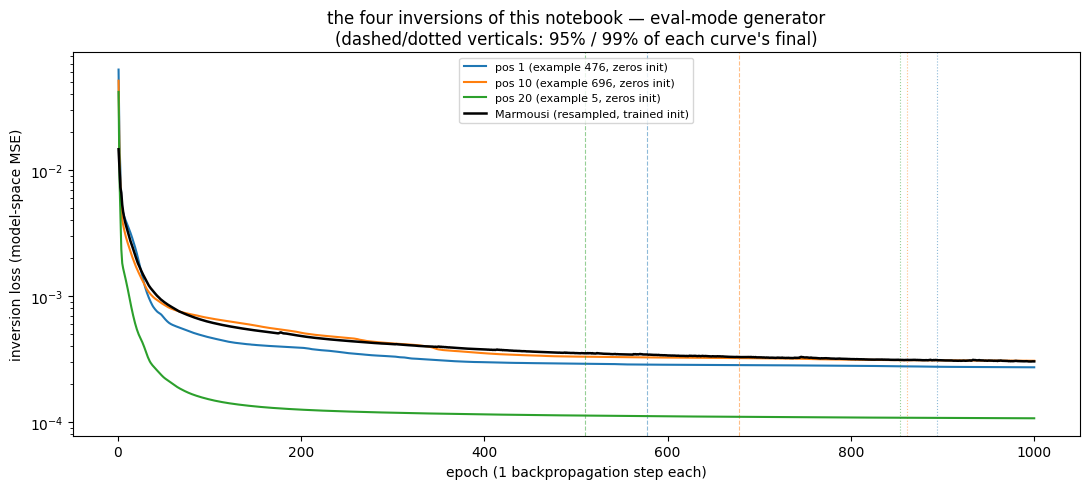

run                                               final       95% at       99% at
Marmousi (trained init)                         0.00030    783 (78%)    956 (96%)
pos 1 (example 476, zeros init)                 0.00027    579 (58%)    895 (90%)
pos 10 (example 696, zeros init)                0.00031    679 (68%)    862 (86%)
pos 20 (example 5, zeros init)                  0.00011    511 (51%)    855 (86%)


In [26]:
# the four inversions made in this notebook — same machinery, same
# config (lr=0.1, 1000 epochs), generator in EVAL mode throughout.
# Inits: Marmousi = trained (the campaign's starting latent); the three
# targets = zeros (per the reachability result, the init does not
# change the floor). Dashed/dotted verticals: 95% / 99% of final.
fig, ax = plt.subplots(figsize=(11, 5))
colors = {1: "C0", 10: "C1", 20: "C2"}
for mi in (1, 10, 20):
    ls_t = re_runs[mi]["losses"]
    ax.plot(range(1, len(ls_t) + 1), ls_t, lw=1.5, color=colors[mi],
            label=f"pos {mi} (example {re_runs[mi]['ex_id']}, zeros init)")
    f95 = next(i for i, v in enumerate(ls_t) if v <= 1.05 * ls_t[-1])
    f99 = next(i for i, v in enumerate(ls_t) if v <= 1.01 * ls_t[-1])
    ax.axvline(f95, color=colors[mi], ls="--", lw=0.8, alpha=0.5)
    ax.axvline(f99, color=colors[mi], ls=":", lw=0.8, alpha=0.5)
ax.plot(range(1, len(losses) + 1), losses, color="k", lw=1.8,
        label="Marmousi (resampled, trained init)")
ax.set_yscale("log")
ax.set_xlabel("epoch (1 backpropagation step each)")
ax.set_ylabel("inversion loss (model-space MSE)")
ax.set_title("the four inversions of this notebook — eval-mode generator\n"
             "(dashed/dotted verticals: 95% / 99% of each curve's final)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

rows = [("Marmousi (trained init)", losses)] + [
    (f"pos {mi} (example {re_runs[mi]['ex_id']}, zeros init)",
     re_runs[mi]["losses"]) for mi in (1, 10, 20)]
print(f"{'run':44s} {'final':>10s} {'95% at':>12s} {'99% at':>12s}")
for name, ls_t in rows:
    f95 = next(i for i, v in enumerate(ls_t) if v <= 1.05 * ls_t[-1])
    f99 = next(i for i, v in enumerate(ls_t) if v <= 1.01 * ls_t[-1])
    n = len(ls_t)
    print(f"{name:44s} {ls_t[-1]:10.5f} "
          f"{f'{f95+1} ({(f95+1)/n*100:.0f}%)':>12s} "
          f"{f'{f99+1} ({(f99+1)/n*100:.0f}%)':>12s}")


---------------------------------------------------
<2026-11-26 00:01:38> GeneratorInversion Constructor!!!
---------------------------------------------------


eval arm (the fix):        final 0.00027
train-mode arm (pin off):  final 0.00050
campaign zeros logged end:       0.00532


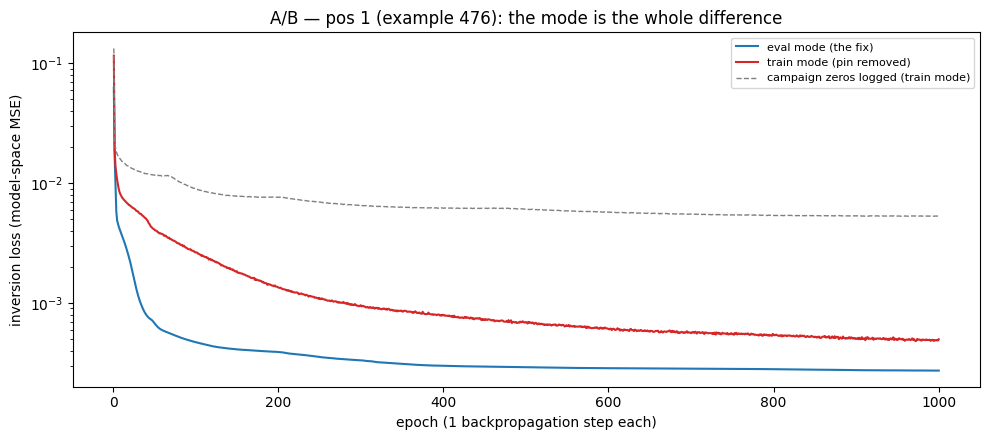

In [27]:
# A/B confirmation — pos 1 (example 476), same target/config, ONLY the
# mode differs: the eval arm is the re-run above; the train-mode arm
# removes the eval-mode pin (default skorch behavior: dropout active,
# BN batch statistics) on a COPY of the generator, so the shared
# module's running statistics are untouched. If the train-mode arm
# plateaus at the campaign's ~0.005 floor, the noise-floor attribution
# is airtight.
import copy
mi = 1
t = (test_true[mi] / absmax)[:672, :800]
y_ab = torch.from_numpy(t[None, None].astype(np.float32)).to(device)

gen_copy = copy.deepcopy(generator.module_)
inv_ab = SkorchGeneratorInversionBuilder().build(
    generator=gen_copy, latent_shape=(1, 512, 21, 25),
    latent_init="zeros", seed=79, max_epochs=1000, device=device, lr=0.1)
inv_ab.initialize()
inv_ab.module_.train = lambda mode=True: torch.nn.Module.train(inv_ab.module_, mode)
inv_ab.partial_fit(torch.zeros_like(y_ab), y_ab)
ab_losses = [h["train_loss"] for h in inv_ab.history]

g1 = camp_curves["zeros"][camp_curves["zeros"]["model_idx"] == mi].sort_values("step")
camp_end = float(g1["value"].iloc[-1])
print(f"eval arm (the fix):        final {re_runs[mi]['losses'][-1]:.5f}")
print(f"train-mode arm (pin off):  final {ab_losses[-1]:.5f}")
print(f"campaign zeros logged end:       {camp_end:.5f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(range(1, len(re_runs[mi]["losses"]) + 1), re_runs[mi]["losses"],
        lw=1.5, label="eval mode (the fix)")
ax.plot(range(1, len(ab_losses) + 1), ab_losses, lw=1.5, color="C3",
        label="train mode (pin removed)")
ax.plot(g1["step"], g1["value"], ls="--", lw=1, color="gray",
        label="campaign zeros logged (train mode)")
ax.set_yscale("log")
ax.set_xlabel("epoch (1 backpropagation step each)")
ax.set_ylabel("inversion loss (model-space MSE)")
ax.set_title(f"A/B — pos {mi} (example {re_runs[mi]['ex_id']}): "
             "the mode is the whole difference")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## The 2×2 decomposition — schedule × mode

The A/B showed the mode (eval vs train) is only ~2×; the campaign's
logged plateau (~0.0053) is dominated by its **lr schedule** —
CosineAnnealingWarmRestarts with T_0=68, T_mult=2, eta_min=1e-6
(verified in the run's own console log: the lr oscillates 0.1→1e-6
with restarts at epochs ~68/204/477, and by epoch 1000 it is
~1e-6–1e-3: the optimization had nearly frozen). This cell runs the
fourth arm — SGDR + eval — completing the 2×2 for pos 1
(example 476), all zeros init, same checkpoint and target.

---------------------------------------------------
<2026-11-26 00:31:32> GeneratorInversion Constructor!!!
---------------------------------------------------


SGDR + eval: final 0.00028


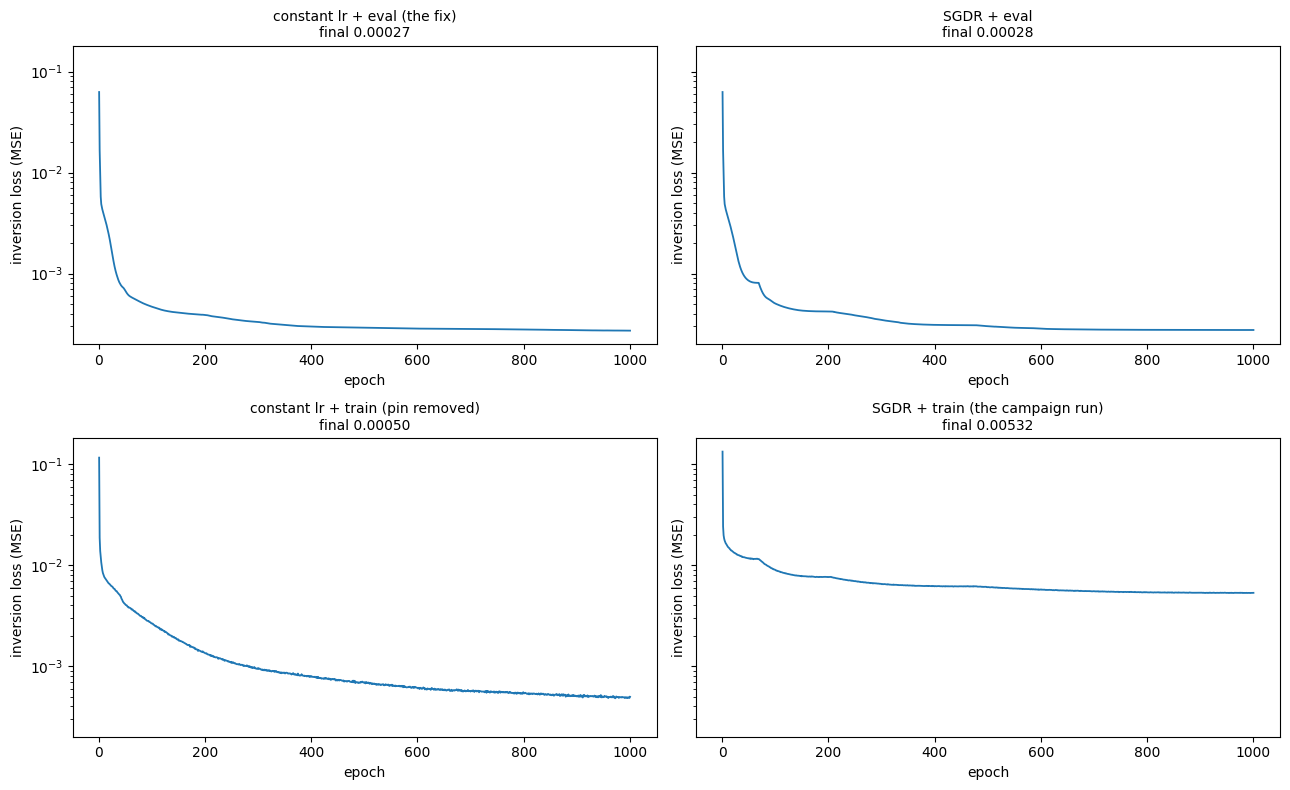

constant+eval 0.00027 | constant+train 0.00050 | SGDR+eval 0.00028 | SGDR+train (campaign) 0.00532
mode effect    (constant lr): 1.82x
schedule effect (train mode): 10.70x
schedule effect (eval mode):  1.01x
total (campaign vs the fix):  19.50x


In [33]:
# the fourth arm: SGDR + eval mode (the campaign's scheduler, the fix's mode)
from skorch.callbacks import LRScheduler
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts

inv_sgdr = SkorchGeneratorInversionBuilder().build(
    generator=generator.module_, latent_shape=(1, 512, 21, 25),
    latent_init="zeros", seed=79, max_epochs=1000, device=device, lr=0.1,
    callbacks=[("lr_scheduler", LRScheduler(
        policy=CosineAnnealingWarmRestarts, T_0=68, T_mult=2,
        eta_min=1e-6))]
)
inv_sgdr.initialize()
inv_sgdr.partial_fit(torch.zeros_like(y_ab), y_ab)
sgdr_eval = [h["train_loss"] for h in inv_sgdr.history]
print(f"SGDR + eval: final {sgdr_eval[-1]:.5f}")

# the 2x2 — schedule (constant vs SGDR) x mode (eval vs train)
g1 = camp_curves["zeros"][camp_curves["zeros"]["model_idx"] == 1].sort_values("step")
panels = [
    (0, 0, re_runs[1]["losses"], "constant lr + eval (the fix)"),
    (0, 1, sgdr_eval, "SGDR + eval"),
    (1, 0, ab_losses, "constant lr + train (pin removed)"),
    (1, 1, list(g1["value"]), "SGDR + train (the campaign run)"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for r, cix, curve, ttl in panels:
    ax = axes[r][cix]
    ax.plot(range(1, len(curve) + 1), curve, lw=1.3)
    ax.set_yscale("log")
    ax.set_title(f"{ttl}\nfinal {curve[-1]:.5f}", fontsize=10)
    ax.set_xlabel("epoch")
for ax in axes.flat:
    ax.set_ylabel("inversion loss (MSE)")
plt.tight_layout()
plt.show()

fe = re_runs[1]["losses"][-1]   # constant + eval (the fix)
ft = ab_losses[-1]              # constant + train
se = sgdr_eval[-1]              # SGDR + eval
st = float(g1["value"].iloc[-1])  # SGDR + train (the campaign)
print(f"constant+eval {fe:.5f} | constant+train {ft:.5f} | "
      f"SGDR+eval {se:.5f} | SGDR+train (campaign) {st:.5f}")
print(f"mode effect    (constant lr): {ft/fe:.2f}x")
print(f"schedule effect (train mode): {st/ft:.2f}x")
print(f"schedule effect (eval mode):  {se/fe:.2f}x")
print(f"total (campaign vs the fix):  {st/fe:.2f}x")


## A second out-of-distribution target: Sigsbee

Same treatment as Marmousi: read the true model from the benchmarks
repo (read-only), resample to the pipeline grid (672, 800), normalize
with the train-fitted per-column abs-max, and invert with the fixed
machinery (trained init — the same starting latent as every inversion
here — eval-mode generator, lr=0.1, 1000 epochs). In the dataset
directory, `sigsbee.npy` is the true velocity model; `sigsbee_init.npy`
(smooth) and the LSRTM image are not used.


file : ../../Benchmarks_FWI_ML/Dados/Sigsbee01/sigsbee.npy
shape: (176, 304)  dtype: float32
range: 1438.5 .. 4511.0
mean : 2653.1


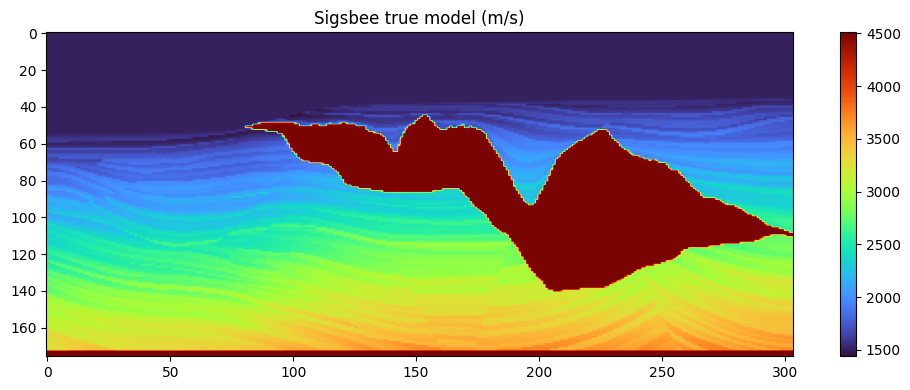

In [34]:
# Sigsbee01 — sibling dataset of Marmousi01 (read-only, like marm_true.npy)
# sigsbee.npy: true velocity model, float32 (176, 304) = depth x lateral
# (same convention as marm_true.npy's (128, 256)); range 1438.5..4511.0 m/s
import numpy as np
from pathlib import Path

CANDIDATES = [
    Path("../../Benchmarks_FWI_ML/Dados/Sigsbee01/sigsbee.npy"),   # repo root
    Path("../../../Benchmarks_FWI_ML/Dados/Sigsbee01/sigsbee.npy"),  # notebooks/
    Path("/tgdesenv/src/proj0/ntbs/doutorado/5semestre.2024.2/estudo.orientado/"
         "projetos/Benchmarks_FWI_ML/Dados/Sigsbee01/sigsbee.npy"),  # host
    Path("/tgdesenv/doutorado/5semestre.2024.2/estudo.orientado/"
         "projetos/Benchmarks_FWI_ML/Dados/Sigsbee01/sigsbee.npy"),  # container
]
SBEE = next(c for c in CANDIDATES if c.exists())
sb = np.load(SBEE)

print(f"file : {SBEE}")
print(f"shape: {sb.shape}  dtype: {sb.dtype}")
print(f"range: {sb.min():.1f} .. {sb.max():.1f}")
print(f"mean : {sb.mean():.1f}")

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(sb, cmap="turbo", aspect="auto")
ax.set_title("Sigsbee true model (m/s)")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


resampled: (672, 800), range 1444.5..4511.0 m/s


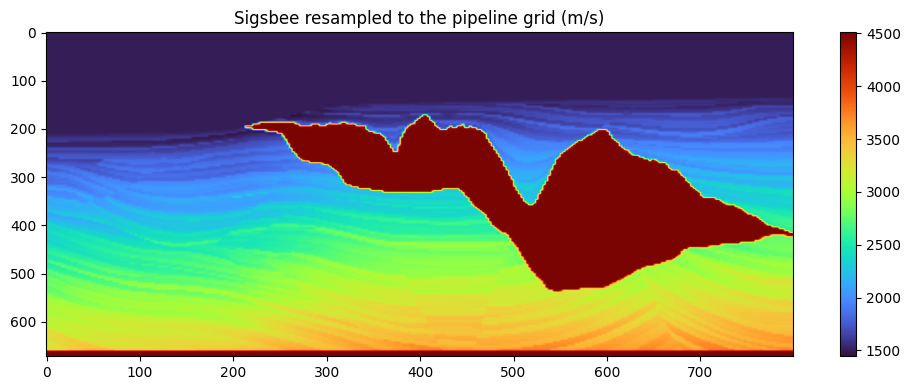

In [35]:
# resample (176, 304) -> (672, 800), still in m/s — the same bilinear
# upsample to the pipeline grid as Marmousi (find_size depth=5)
import torch

NZ, NX = 672, 800
sb_up = torch.nn.functional.interpolate(
    torch.from_numpy(sb[None, None].astype(np.float32)),
    size=(NZ, NX), mode="bilinear", align_corners=False)[0, 0].numpy()
print(f"resampled: {sb_up.shape}, range {sb_up.min():.1f}..{sb_up.max():.1f} m/s")

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(sb_up, cmap="turbo", aspect="auto")
ax.set_title("Sigsbee resampled to the pipeline grid (m/s)")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


normalized Sigsbee: range 0.347..1.084
(values > 1: columns where Sigsbee exceeds the train split's abs-max — expected around the salt)


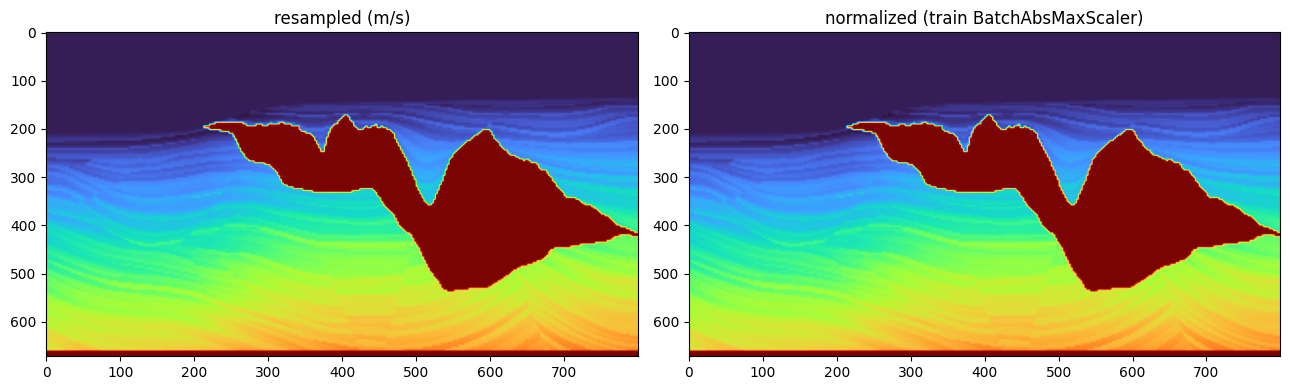

In [36]:
# the same train-fitted BatchAbsMaxScaler as Marmousi (cell 6's `absmax`,
# one abs-max per lateral column) — not refitted: the scaler is the
# campaign's; Sigsbee is just another model mapped through it
sbee_ds = sb_up / absmax
print(f"normalized Sigsbee: range {sbee_ds.min():.3f}..{sbee_ds.max():.3f}")
print("(values > 1: columns where Sigsbee exceeds the train split's "
      "abs-max — expected around the salt)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.imshow(sb_up, cmap="turbo", aspect="auto")
ax1.set_title("resampled (m/s)")
ax2.imshow(sbee_ds, cmap="turbo", aspect="auto")
ax2.set_title("normalized (train BatchAbsMaxScaler)")
plt.tight_layout()
plt.show()


In [37]:
# invert Sigsbee with the fixed machinery — the campaign's trained init
# (Encoder of train example 182, the same starting latent as every
# inversion in this notebook), eval-mode generator (the
# GeneratorInversion pin), lr=0.1, 1000 epochs
x_init = ((raw_train[10] / absmax)[:672, :800])[None, None].astype(np.float32)
z0_sbee = encoder.predict(torch.from_numpy(x_init).to(device))

y_sbee = torch.from_numpy(sbee_ds[None, None].astype(np.float32)).to(device)
inv_sbee = SkorchGeneratorInversionBuilder().build(
    generator=generator.module_, latent_shape=(1, 512, 21, 25),
    latent_init="trained", seed=79, max_epochs=1000, device=device, lr=0.1)
inv_sbee.initialize()
inv_sbee.module_.set_latent(z0_sbee)   # the campaign's trained start
inv_sbee.partial_fit(torch.zeros_like(y_sbee), y_sbee)

sbee_losses = [h["train_loss"] for h in inv_sbee.history]
sbee_final = sbee_losses[-1]
sbee_95 = next(i for i, v in enumerate(sbee_losses) if v <= 1.05 * sbee_final)
sbee_99 = next(i for i, v in enumerate(sbee_losses) if v <= 1.01 * sbee_final)
z_sbee = inv_sbee.module_.latent.detach()
sbee_rec = generator.module_(z_sbee)[0, 0].detach().cpu().numpy()
print(f"final MSE {sbee_final:.5f} | 95% at epoch {sbee_95 + 1}, "
      f"99% at epoch {sbee_99 + 1} (of {len(sbee_losses)})")


---------------------------------------------------
<2026-11-26 00:31:51> GeneratorInversion Constructor!!!
---------------------------------------------------
final MSE 0.00076 | 95% at epoch 577, 99% at epoch 885 (of 1000)


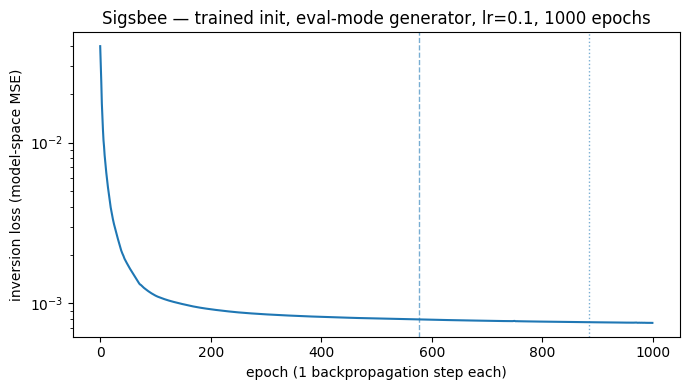

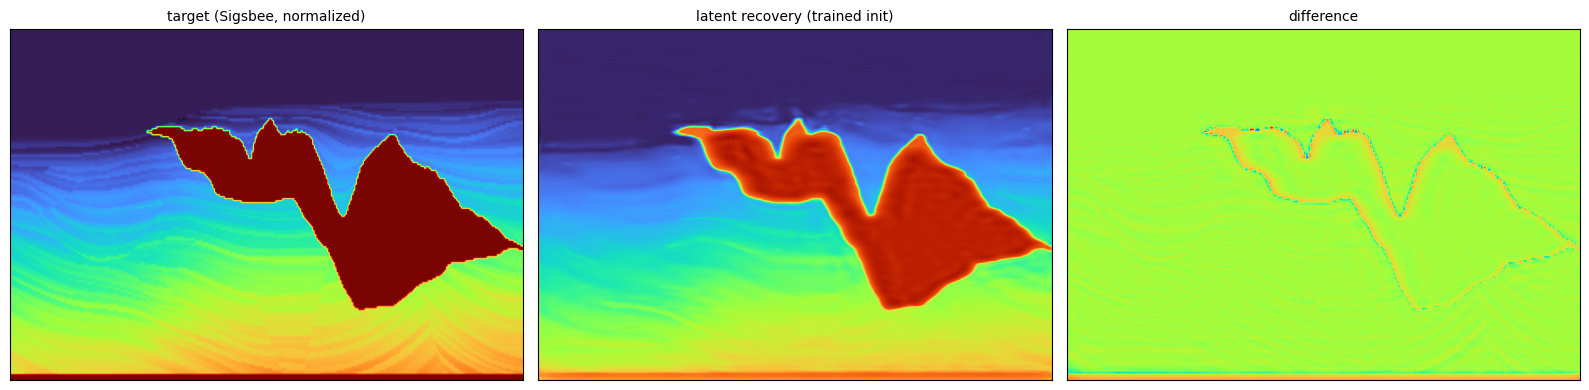

In [38]:
# results — loss curve (with the pack's 95%/99% marks) and the recovery
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sbee_losses)
ax.axvline(sbee_95, ls="--", lw=1, alpha=0.6)
ax.axvline(sbee_99, ls=":", lw=1, alpha=0.6)
ax.set_yscale("log")
ax.set_xlabel("epoch (1 backpropagation step each)")
ax.set_ylabel("inversion loss (model-space MSE)")
ax.set_title("Sigsbee — trained init, eval-mode generator, lr=0.1, 1000 epochs")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, img, ttl in zip(axes, [sbee_ds, sbee_rec, sbee_ds - sbee_rec],
                        ["target (Sigsbee, normalized)",
                         "latent recovery (trained init)",
                         "difference"]):
    ax.imshow(img, cmap="turbo", aspect="auto")
    ax.set_title(ttl, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()


## Trust audit — is anything here too good?

Two results deserve scrutiny: the inversion landing **below** the
encoder-decoder's own reconstruction, and the benchmarks being
recovered at all.

**Code-level checks (review, this repo):** the generator is frozen
during inversion (`requires_grad=False` in `GeneratorInversion.__init__`,
`ml_models.py`), so Adam moves only the latent — no weight updates are
possible; `set_latent` is in-place (`copy_`), so the optimizer never
holds a stale reference; the eval pin changes no weights (dropout off,
BatchNorm running stats, as at inference); one latent step per epoch
(batch_size=1, shuffle off); the abs-max scaler is fitted on the train
split only; the three targets are test-split examples the AE never
trained on; targets and reconstructions are compared on the same
(672, 800) grid the AE operates on.

**Framing:** the recovery is a *fit* — 1000 supervised gradient steps
against the true model — so its MSE is an in-sample bound, while the
encoder-decoder column is the learned one-pass mapping (a
*prediction*). The inversion winning that comparison says the latent
space can represent the target better than the encoder maps it there:
the bottleneck is the encoder, not the latent. The FWI-relevant
question (does the seismic misfit find the same latent?) is open.

**The one thing code review cannot settle** is dataset composition:
the repo does not document how the 1000 models were generated. If
they derive from Marmousi/Sigsbee (crops, perturbations), the
benchmarks are in-distribution and "generalization" is interpolation.
This cell measures it: nearest-neighbor relative L2,
d(x, b) = ‖x − b‖/‖b‖, between each benchmark and all 1000 dataset
models (the notebook's exact preprocessing), calibrated against
distances among the dataset models themselves.

**Outcome (run 2026-11-26)**: Marmousi's NN rel-L2 is **0.169** (train
example 737), Sigsbee's **0.269** (train example 198), against a
dataset-internal calibration of p5 **0.143** / median **0.185** (60
models, 1770 pairs). No benchmark has an anomalously close neighbor —
nothing near copy level (≪ p5): no leakage. The nuance: Marmousi's NN
sits *inside* the dataset's own pairwise spread, below its median —
the resampled Marmousi is structurally one of the closest models to
the training set (near-distribution, though never trained on);
Sigsbee's NN is *above* the dataset median — genuinely harder than a
typical dataset pair. Thesis wording: "not in the training set" for
Marmousi; Sigsbee earns "out-of-distribution".


Marmousi: NN rel-L2 0.169 (dataset train model at position 658, example 737) | p5 0.184 median 0.202
Sigsbee : NN rel-L2 0.269 (dataset train model at position 832, example 198) | p5 0.283 median 0.307
dataset-vs-dataset calibration (60 models, 1770 pairs): p5 0.143, median 0.185
reading: NN well below the calibration range -> the benchmark is
         (a crop of) material the AE saw: the OOD claim dies.
         NN within the calibration range -> genuinely out-of-
         distribution; the generalization is real.


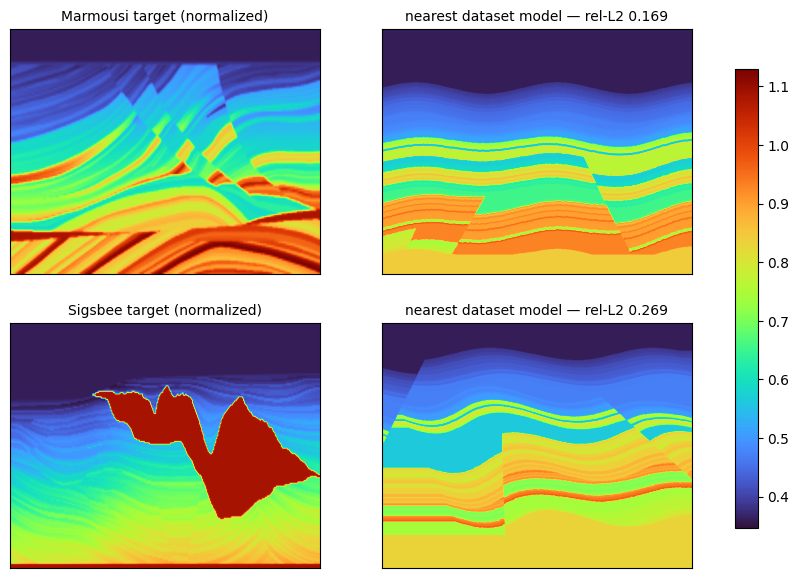

In [40]:
# nearest-neighbor audit: each benchmark vs all 1000 dataset models,
# calibrated against dataset-internal distances (60 sampled models)
bench = {"Marmousi": m_ds, "Sigsbee": sbee_ds}


def norm_crop(m):
    return (m / absmax)[:672, :800]


def rel_l2(x, b):
    return float(np.linalg.norm(x - b) / np.linalg.norm(b))


n_train = len(raw_train)
d_bench = {k: [] for k in bench}
for arr in (raw_train, test_true):
    for i in range(len(arr)):
        x = norm_crop(arr[i])
        for k, b in bench.items():
            d_bench[k].append(rel_l2(x, b))

def get_model(j):
    return raw_train[j] if j < n_train else test_true[j - n_train]


rng = np.random.default_rng(0)
samped = [norm_crop(get_model(int(j)))
          for j in rng.choice(n_train + len(test_true), size=60,
                              replace=False)]
d_cal = np.array([rel_l2(samped[a], samped[b])
                  for a in range(len(samped))
                  for b in range(a + 1, len(samped))])

for k, b in bench.items():
    d = np.array(d_bench[k])
    j = int(d.argmin())
    where = "train" if j < n_train else "test"
    ex = (int(train_indexes[j]) if j < n_train
          else int(test_indexes[j - n_train]))
    print(f"{k:8s}: NN rel-L2 {d.min():.3f} (dataset {where} model at "
          f"position {j}, example {ex}) | p5 {np.percentile(d, 5):.3f} "
          f"median {np.median(d):.3f}")
print(f"dataset-vs-dataset calibration (60 models, {len(d_cal)} pairs): "
      f"p5 {np.percentile(d_cal, 5):.3f}, median {np.median(d_cal):.3f}")
print("reading: NN well below the calibration range -> the benchmark is")
print("         (a crop of) material the AE saw: the OOD claim dies.")
print("         NN within the calibration range -> genuinely out-of-")
print("         distribution; the generalization is real.")

vmin = min(min(b.min(), norm_crop(get_model(int(np.argmin(d_bench[k])))).min())
           for k, b in bench.items())
vmax = max(max(b.max(), norm_crop(get_model(int(np.argmin(d_bench[k])))).max())
           for k, b in bench.items())
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for r, (k, b) in enumerate(bench.items()):
    j = int(np.argmin(d_bench[k]))
    x = norm_crop(get_model(j))
    im = axes[r][0].imshow(b, cmap="turbo", aspect="auto",
                           vmin=vmin, vmax=vmax)
    axes[r][0].set_title(f"{k} target (normalized)", fontsize=10)
    axes[r][1].imshow(x, cmap="turbo", aspect="auto",
                      vmin=vmin, vmax=vmax)
    axes[r][1].set_title(f"nearest dataset model — rel-L2 "
                         f"{d_bench[k][j]:.3f}", fontsize=10)
    for c in (0, 1):
        axes[r][c].set_xticks([]); axes[r][c].set_yticks([])
fig.colorbar(im, ax=list(axes.flat), shrink=0.85)
plt.show()


In [41]:
# runtime confirmation of the audit's code-review claim: the generator's
# weights are byte-identical before and after a full inversion — only the
# latent moves. requires_grad=False on the generator is the code-level
# guarantee; this is the measured one (pos 1, trained init, same config).
h0 = torch.nn.utils.parameters_to_vector(
    generator.module_.parameters()).detach().clone()

t1 = (test_true[1] / absmax)[:672, :800]
y1 = torch.from_numpy(t1[None, None].astype(np.float32)).to(device)
x1i = ((raw_train[10] / absmax)[:672, :800])[None, None].astype(np.float32)
z0_chk = encoder.predict(torch.from_numpy(x1i).to(device))

inv_chk = SkorchGeneratorInversionBuilder().build(
    generator=generator.module_, latent_shape=(1, 512, 21, 25),
    latent_init="trained", seed=79, max_epochs=1000, device=device, lr=0.1)
inv_chk.initialize()
inv_chk.module_.set_latent(z0_chk)
inv_chk.partial_fit(torch.zeros_like(y1), y1)

h1 = torch.nn.utils.parameters_to_vector(
    generator.module_.parameters()).detach()
n_par = sum(p.numel() for p in generator.module_.parameters())
print(f"generator parameters: {n_par:,}")
print(f"byte-identical after a full 1000-epoch inversion: "
      f"{torch.equal(h0, h1)}")
print(f"max |delta weight|: {(h1 - h0).abs().max().item():.3e}")
print(f"check-run final MSE "
      f"{inv_chk.history[-1]['train_loss']:.5f} (reproduces the pos-1 "
      "inversion above)")


---------------------------------------------------
<2026-11-26 01:11:29> GeneratorInversion Constructor!!!
---------------------------------------------------
generator parameters: 5,066,657
byte-identical after a full 1000-epoch inversion: True
max |delta weight|: 0.000e+00
check-run final MSE 0.00026 (reproduces the pos-1 inversion above)


## All examples — true model, encoder-decoder reconstruction, inversion

Three columns per row, all fields in m/s (the per-column train absmax
undone), one shared color scale: the **true model**; the
**encoder-decoder reconstruction** (one Encoder→Generator pass on the
true model — the AE's own prediction, a single forward pass, no
optimization); and the **inverted model** (latent optimization from the
campaign's trained init, eval-mode generator, lr=0.1, 1000 epochs).
Rows: Marmousi, the campaign's three test targets, and Sigsbee (that
last row appears once the Sigsbee section above has run). MSEs in the
panel titles are in normalized units, computed uniformly as
mean((img − true)²); the AE-recon column is the built-in benchmark (the
refit model's prediction MSE is ~0.0005–0.0011 on the dataset targets).
Marmousi's inversion comes from cell 9; the three targets are
re-inverted here (the control cell ran zeros init and reused `inv` —
its zeros-init finals are printed for contrast).


trained latent from train example 182
---------------------------------------------------
<2026-11-26 00:32:21> GeneratorInversion Constructor!!!
---------------------------------------------------
pos 1: trained-init final MSE 0.00026 (zeros init was 0.00027)
---------------------------------------------------
<2026-11-26 00:32:33> GeneratorInversion Constructor!!!
---------------------------------------------------
pos 10: trained-init final MSE 0.00030 (zeros init was 0.00031)
---------------------------------------------------
<2026-11-26 00:32:45> GeneratorInversion Constructor!!!
---------------------------------------------------
pos 20: trained-init final MSE 0.00012 (zeros init was 0.00011)
Marmousi: kernel recovery (trained init), final MSE 0.00030
Sigsbee row added (final MSE 0.00076)


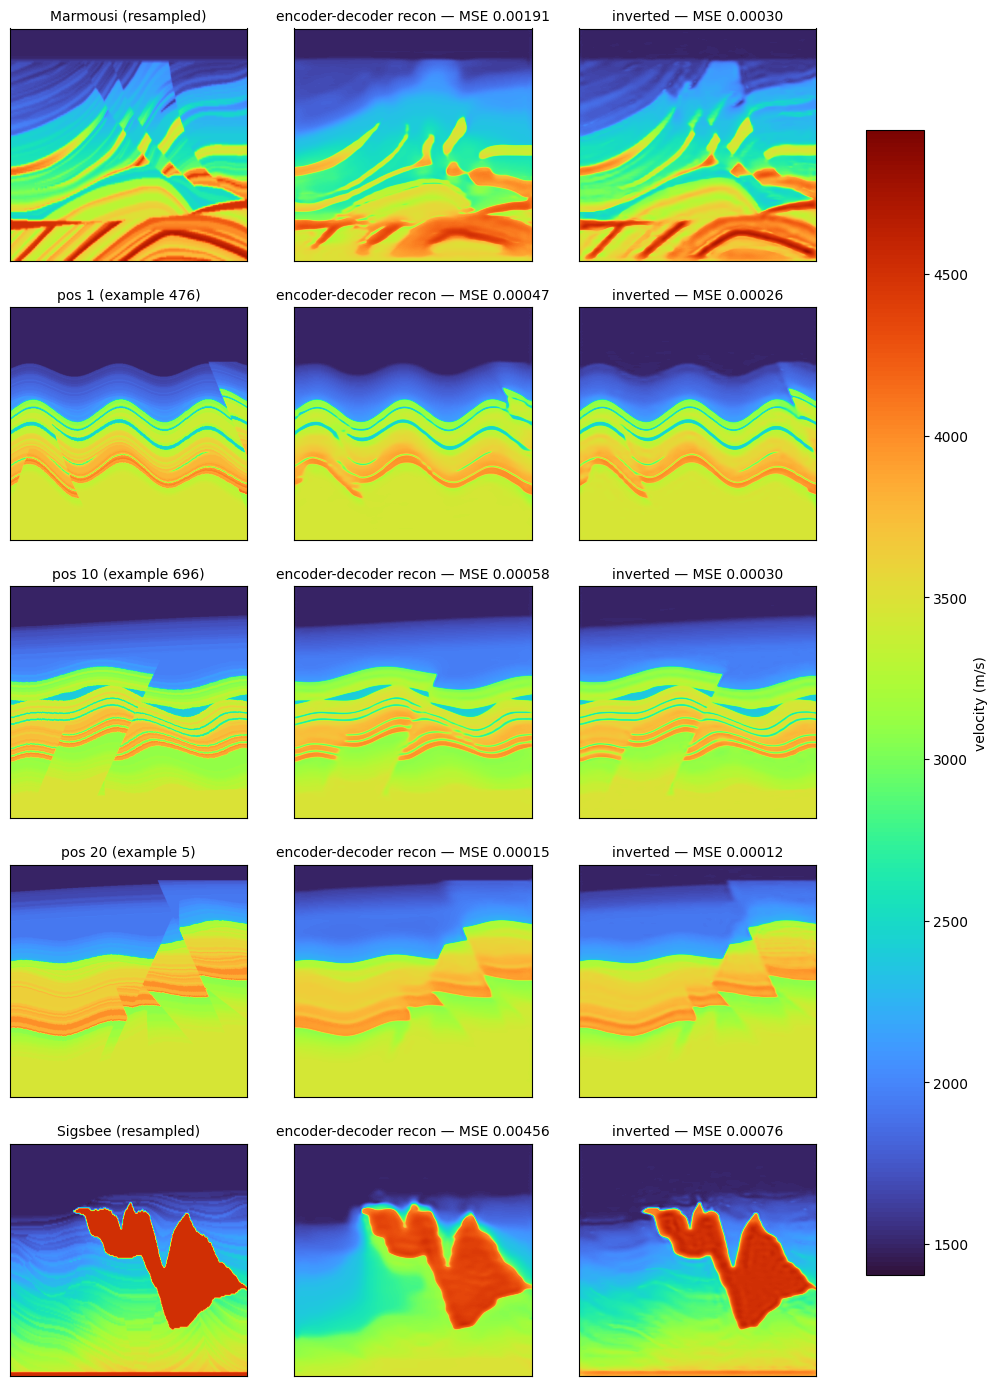

In [39]:
# the examples — three columns per row: the true model, the
# encoder-decoder reconstruction (one Encoder->Generator pass on the true
# model: the AE's own prediction, no optimization), and the latent inversion
# (trained init, eval-mode fix, lr=0.1, 1000 epochs). All fields in m/s
# (per-column train absmax undone); MSEs in normalized units, computed
# uniformly as mean((img - true)**2).
x_init = ((raw_train[10] / absmax)[:672, :800])[None, None].astype(np.float32)
z0 = encoder.predict(torch.from_numpy(x_init).to(device))
print("trained latent from train example", int(train_indexes[10]))


def ae_reconstruction(x_np):
    z = encoder.predict(
        torch.from_numpy(x_np[None, None].astype(np.float32)).to(device))
    with torch.no_grad():
        return generator.module_(
            torch.from_numpy(z).to(device))[0, 0].detach().cpu().numpy()


rows = [("Marmousi (resampled)", m_ds, ae_reconstruction(m_ds), rec)]
for mi in (1, 10, 20):
    t = (test_true[mi] / absmax)[:672, :800]
    y_t = torch.from_numpy(t[None, None].astype(np.float32)).to(device)
    inv_t = SkorchGeneratorInversionBuilder().build(
        generator=generator.module_, latent_shape=(1, 512, 21, 25),
        latent_init="trained", seed=79, max_epochs=1000, device=device,
        lr=0.1)
    inv_t.initialize()
    inv_t.module_.set_latent(z0)   # the campaign's trained start
    inv_t.partial_fit(torch.zeros_like(y_t), y_t)
    z_t = inv_t.module_.latent.detach()
    r = generator.module_(z_t)[0, 0].detach().cpu().numpy()
    re_runs[mi]["losses_trained"] = [h["train_loss"] for h in inv_t.history]
    re_runs[mi]["rec_trained"] = r
    rows.append((f"pos {mi} (example {re_runs[mi]['ex_id']})",
                 t, ae_reconstruction(t), r))
    print(f"pos {mi}: trained-init final MSE "
          f"{inv_t.history[-1]['train_loss']:.5f} (zeros init was "
          f"{re_runs[mi]['losses'][-1]:.5f})")
print(f"Marmousi: kernel recovery (trained init), final MSE {losses[-1]:.5f}")

# Sigsbee row — available once the Sigsbee section above has run
if "sbee_ds" in globals() and "sbee_rec" in globals():
    rows.append(("Sigsbee (resampled)", sbee_ds,
                 ae_reconstruction(sbee_ds), sbee_rec))
    print(f"Sigsbee row added (final MSE "
          f"{inv_sbee.history[-1]['train_loss']:.5f})")
else:
    print("Sigsbee row skipped — run the Sigsbee section above first")

disp = [(name, t * absmax, a * absmax, i * absmax)
        for name, t, a, i in rows]
vmin = min(min(t.min(), a.min(), i.min()) for _, t, a, i in disp)
vmax = max(max(t.max(), a.max(), i.max()) for _, t, a, i in disp)
fig, axes = plt.subplots(len(disp), 3, figsize=(13, 3.5 * len(disp)))
for r_i, (name, t_ms, a_ms, i_ms) in enumerate(disp):
    t_n, a_n, i_n = rows[r_i][1], rows[r_i][2], rows[r_i][3]
    panels = [(t_ms, name, None),
              (a_ms, "encoder-decoder recon",
               float(((a_n - t_n) ** 2).mean())),
              (i_ms, "inverted", float(((i_n - t_n) ** 2).mean()))]
    for c_i, (img, lab, mse) in enumerate(panels):
        ax = axes[r_i][c_i]
        im = ax.imshow(img, cmap="turbo", aspect="auto", vmin=vmin, vmax=vmax)
        ax.set_title(lab if mse is None else f"{lab} — MSE {mse:.5f}",
                     fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=list(axes.flat), shrink=0.85, label="velocity (m/s)")
plt.show()
